In [32]:
import math
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

In [33]:
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams.update({
    "font.size": 14,          # Общий размер шрифта
    "axes.titlesize": 16,     # Заголовки графиков
    "axes.labelsize": 14,     # Подписи осей
    "xtick.labelsize": 12,    # Подписи делений X
    "ytick.labelsize": 12,    # Подписи делений Y
    "legend.fontsize": 12,    # Легенда
    "figure.titlesize": 18    # Общий заголовок рисунка
})

In [34]:
RANDOM_STATE = 42

X_MIN = 0.0
X_MAX = 1

FUNCTIONS = {
    "cos(2πx)": lambda x: np.cos(2 * np.pi * x),
    "5x^3 + x^2 + 5": lambda x: 5 * x**3 + x**2 + 5,
    "x sin(2πx)": lambda x: x * np.sin(2 * np.pi * x),
}

N_VALUES = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 125, 250, 500, 750, 1000, 1250, 2500, 5000, 7500, 10000]
DEFAULT_N = 500

NOISE_VALUES = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 2, 10]
DEFAULT_NOISE = 0.1

In [35]:
from typing import Protocol

class Layer(Protocol):
    def forward(self, x: np.ndarray) -> np.ndarray:
        ...

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float) -> np.ndarray:
        ...


In [36]:
class Linear:
    def __init__(self, in_features, out_features, random_state: int):
        self.in_features = in_features
        self.out_features = out_features
        self.random_state = random_state

        rng = np.random.RandomState(random_state)

        w_sigma = math.sqrt(2 / in_features)
        self.w = rng.randn(in_features, out_features, ) * w_sigma
        self.b = np.zeros(out_features)

    def forward(self, x: np.ndarray) -> np.ndarray:
        return np.dot(x, self.w) + self.b

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float) -> np.ndarray:
        reshaped_grad = grad
        reshaped_x = x

        de_dx = np.dot(grad, self.w.T)
        de_dw = np.dot(reshaped_x.T, reshaped_grad).reshape(self.w.shape)
        de_db = grad.reshape(self.b.shape)

        self.w -= lr * de_dw
        self.b -= lr * de_db

        return de_dx

    def __str__(self) -> str:
        return f"Linear(in_features={self.in_features}, out_features={self.out_features}, random_state={self.random_state})"


In [37]:
class IdentityActivation:
    def forward(self, x: np.ndarray) -> np.ndarray:
        return x

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float):
        return grad

    def __str__(self) -> str:
        return "IdentityActivation()"


In [38]:
class ReLuActivation:
    def forward(self, x: np.ndarray) -> np.ndarray:
        return np.maximum(0, x)

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float):
        return grad * (x > 0)

    def __str__(self) -> str:
        return f"ReLuActivation()"


In [39]:
class LeakyReLuActivation:
    def __init__(self, alpha: float = 0.1):
        self.alpha = alpha

    def forward(self, x: np.ndarray) -> np.ndarray:
        return np.where(x >= 0, x, self.alpha * x)

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float):
        return np.where(x >= 0, 1.0, self.alpha) * grad

    def __str__(self) -> str:
        return f"LeakyReLuActivation(alpha={self.alpha})"


In [40]:
class TanhActivation:
    def __init__(self, alpha: float = 0.1):
        self.alpha = alpha

    def forward(self, x: np.ndarray) -> np.ndarray:
        return np.tanh(x)

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float) -> np.ndarray:
        return grad * (1 - self.forward(x) ** 2)

    def __str__(self) -> str:
        return "TanhActivation()"


In [41]:
class SigmoidActivation:
    def forward(self, x: np.ndarray) -> np.ndarray:
        return 1 / (1 + np.exp(-x))

    def backward(self, x: np.ndarray, grad: np.ndarray, lr: float) -> np.ndarray:
        sigmoid = self.forward(x)
        return grad * sigmoid * (1 - sigmoid)

    def __str__(self) -> str:
        return "SigmoidActivation()"


In [42]:
def Activation(name: str) -> Layer:
    if name == "identity":
        return IdentityActivation()

    if name == "relu":
        return ReLuActivation()

    if name == "leaky-relu":
        return LeakyReLuActivation()

    if name == "tanh":
        return TanhActivation()

    if name == "sigmoid":
        return SigmoidActivation()

    raise Exception(f"Unsupported activation: '{name}'")

In [43]:
from sklearn.base import BaseEstimator, RegressorMixin

class Model(RegressorMixin, BaseEstimator):
    def __init__(
            self,
            hidden_count,
            hidden_size,
            activation,
            learning_rate,
            epochs,
            show_progress,
            random_state,
    ):
        self.hidden_count = hidden_count
        self.hidden_size = hidden_size
        self.activation = activation
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.show_progress = show_progress
        self.random_state = random_state

    def fit(self, X, y, early_stopping=False, X_val=None, y_val=None, patience=10):
        self.__init_layers()

        rng = np.random.default_rng(self.random_state)

        best_loss = float('inf')
        counter = 0
        if early_stopping:
            if X_val is None or y_val is None:
                raise ValueError(
                    "X_val and y_val are required "
                    "when early_stopping=True"
                )

        epochs_passed = 0
        with tqdm(total=self.epochs * len(X), desc="Training", disable=not self.show_progress):
            for epoch in range(self.epochs):
                self.__train_epoch(rng, X, y)

                epochs_passed += 1

                if not early_stopping:
                    continue

                val_pred = self.predict(X_val)
                val_loss = np.mean((y_val - val_pred) ** 2)

                if val_loss < best_loss:
                    best_loss = val_loss
                    counter = 0
                    best_weights = self.__get_weights()
                else:
                    counter += 1

                if counter >= patience:
                    break

        if early_stopping:
            self.__set_weights(best_weights)

        return epochs_passed

    def predict(self, X):
        result = X.reshape(-1, 1)

        for layer in self.layers_:
            result = layer.forward(result)

        result = result.reshape(-1)

        if not np.all(np.isfinite(result)):
            raise FloatingPointError("Result is not finite")

        return result

    def __train_epoch(self, rng, X, y) -> None:
        indices = rng.permutation(len(X))

        for i in indices:
            x = X[i]
            y_true = y[i]

            inputs = [x]

            for l in self.layers_:
                inputs.append(l.forward(inputs[-1]))

            y_pred = inputs.pop(-1)
            mse_grad = y_pred - y_true
            grad = mse_grad

            for x_in, l in zip(inputs[::-1], self.layers_[::-1]):
                grad = l.backward(x_in, grad, lr=self.learning_rate)

    def __init_layers(self) -> None:
        self.layers_ = []

        self.layers_.extend([
            Linear(1, self.hidden_size, self.random_state),
            Activation(self.activation),
        ])

        for i in range(self.hidden_count):
            self.layers_.extend([
                Linear(
                    self.hidden_size,
                    self.hidden_size,
                    self.random_state + i + 1,
                ),
                Activation(self.activation),
            ])

        self.layers_.extend([
            Linear(
                self.hidden_size,
                1,
                self.random_state + self.hidden_count + 1,
            ),
            Activation("identity"),
        ])

    def __get_weights(self):
        weights = []

        for layer in self.layers_:
            if isinstance(layer, Linear):
                weights.append({
                    "weights": layer.w.copy(),
                    "bias": layer.b.copy()
                })

        return weights

    def __set_weights(self, weights):
        linear_layers = [
            layer for layer in self.layers_
            if isinstance(layer, Linear)
        ]

        for layer, params in zip(linear_layers, weights):
            layer.w = params["weights"].copy()
            layer.b = params["bias"].copy()


In [44]:
def noise_sigma(func, noise_fraction):
    y_ref = func(np.linspace(X_MIN, X_MAX, 10001))
    return noise_fraction * np.ptp(y_ref)


def make_sample(func, n, noise_fraction, rng):
    x = rng.uniform(X_MIN, X_MAX, size=n)
    sigma = noise_sigma(func, noise_fraction)
    eps = rng.normal(loc=0.0, scale=sigma, size=n)
    y = func(x) + eps
    order = np.argsort(x)
    return {"x": x[order], "y": y[order]}

def make_sample_without_noise(func, rng, n=1000):
    x = rng.uniform(X_MIN, X_MAX, size=n)
    y = func(x)
    order = np.argsort(x)
    return {"x": x[order], "y": y[order]}


In [45]:
rng = np.random.default_rng(RANDOM_STATE)

train_samples = {}
for func_name, func in FUNCTIONS.items():
    for n in N_VALUES:
        for noise_fraction in NOISE_VALUES:
            train_samples[(func_name, n, noise_fraction)] = make_sample(func, n, noise_fraction, rng)

test_samples = {}
for func_name, func in FUNCTIONS.items():
    test_samples[func_name] = make_sample_without_noise(func, rng, 1000)


In [46]:
configurations_by_activation = {
    "cos(2πx)": {
        "relu": {
            "hidden_count": 7,
            "hidden_size": 116,
            "activation": "relu",
            "learning_rate": 0.006555404555943717,
            "epochs": 66,
        },
        "leaky-relu": {
            "hidden_count": 6,
            "hidden_size": 39,
            "activation": "leaky-relu",
            "learning_rate": 0.014241873698697153,
            "epochs": 21,
        },
        "sigmoid": {
            "hidden_count": 0,
            "hidden_size": 91,
            "activation": "sigmoid",
            "learning_rate": 0.14573113682016034,
            "epochs": 21,
        },
        "tanh": {
            "hidden_count": 10,
            "hidden_size": 116,
            "activation": "tanh",
            "learning_rate": 0.00015696928046478537,
            "epochs": 21,
        },
    },
    "5x^3 + x^2 + 5": {
        "relu": {
            "hidden_count": 1,
            "hidden_size": 113,
            "activation": "relu",
            "learning_rate": 0.025090508733230144,
            "epochs": 23,
        },
        "leaky-relu": {
            "hidden_count": 5,
            "hidden_size": 35,
            "activation": "leaky-relu",
            "learning_rate": 0.00955960198906801,
            "epochs": 1000,
        },
        "sigmoid": {
            "hidden_count": 1,
            "hidden_size": 92,
            "activation": "sigmoid",
            "learning_rate": 0.0688111677338788,
            "epochs": 24,
        },
        "tanh": {
            "hidden_count": 0,
            "hidden_size": 17,
            "activation": "tanh",
            "learning_rate": 0.05313551324081298,
            "epochs": 25,
        },
    },
    "x sin(2πx)": {
        "relu": {
            "hidden_count": 7,
            "hidden_size": 25,
            "activation": "relu",
            "learning_rate": 0.05427992385012899,
            "epochs": 42,
        },
        "leaky-relu": {
            "hidden_count": 5,
            "hidden_size": 10,
            "activation": "leaky-relu",
            "learning_rate": 0.048706478916175154,
            "epochs": 32,
        },
        "sigmoid": {
            "hidden_count": 1,
            "hidden_size": 94,
            "activation": "sigmoid",
            "learning_rate": 0.15154052031106816,
            "epochs": 86,
        },
        "tanh": {
            "hidden_count": 9,
            "hidden_size": 85,
            "activation": "tanh",
            "learning_rate": 0.0029312113726972138,
            "epochs": 42,
        },
    },
}


In [47]:
best_configurations = {
    "cos(2πx)": configurations_by_activation["cos(2πx)"]["tanh"],
    "5x^3 + x^2 + 5": configurations_by_activation["5x^3 + x^2 + 5"]["relu"],
    "x sin(2πx)": configurations_by_activation["x sin(2πx)"]["tanh"]
}


In [48]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_percentage_error

def score_model(model, X_train, y_train, X_test, y_test) -> tuple[float, float, int]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_true = y_test

    return (
        r2_score(y_true, y_pred),
        int(mean_absolute_percentage_error(y_true, y_pred) * 100),
        root_mean_squared_error(y_true, y_pred),
    )


In [49]:
import os
import json

if os.path.exists("results.json"):
    results = json.load(open("results.json"))
    need_to_score = False
else:
    results = {}
    need_to_score = True

In [50]:
results["best"] = {}
best_models = {}

for func_name in best_configurations:
    X_train = train_samples[(func_name, DEFAULT_N, DEFAULT_NOISE)]["x"]
    y_train = train_samples[(func_name, DEFAULT_N, DEFAULT_NOISE)]["y"]

    X_test = test_samples[func_name]["x"]
    y_test = test_samples[func_name]["y"]

    best_conf = best_configurations[func_name]
    model = Model(
        hidden_count=best_conf["hidden_count"],
        hidden_size=best_conf["hidden_size"],
        learning_rate=best_conf["learning_rate"],
        activation=best_conf["activation"],
        epochs=best_conf["epochs"],
        show_progress=False,
        random_state=RANDOM_STATE,
    )

    r2, mape, rmse = score_model(model, X_train, y_train, X_test, y_test)
    best_models[func_name] = model

    results["best"][func_name] = {
        **best_conf,
        "r2": r2,
        "mape": mape,
        "rmse": rmse,
    }


In [51]:
import pandas as pd
from IPython.display import display

METRICS = [
    ("r2", "R²"),
    ("mape", "MAPE, %"),
    ("rmse", "RMSE"),
]


In [52]:
print("Best configurations (noise_level = 0.1, n = 500)")

BEST_TABLE_COLUMNS = [
    "Function",
    "R²", "MAPE, %", "RMSE",
    "hidden_count", "hidden_size", "activation", "learning_rate", "epochs",
]
best_rows = []
for func_name, values in results["best"].items():
    best_rows.append({
        "Function": func_name,
        "R²": values["r2"],
        "MAPE, %": values["mape"],
        "RMSE": values["rmse"],
        "hidden_count": values["hidden_count"],
        "hidden_size": values["hidden_size"],
        "activation": values["activation"],
        "learning_rate": values["learning_rate"],
        "epochs": values["epochs"],
    })

best_configurations_table = pd.DataFrame(best_rows, columns=BEST_TABLE_COLUMNS)
display(best_configurations_table)

Best configurations (noise_level = 0.1, n = 500)


,Function,R²,"MAPE, %",RMSE,hidden_count,hidden_size,activation,learning_rate,epochs
0,cos(2πx),0.990200,34,0.070626,10,116,tanh,0.000157,21
1,5x^3 + x^2 + 5,0.995086,1,0.114134,1,113,relu,0.025091,23
2,x sin(2πx),0.986843,104254,0.042624,9,85,tanh,0.002931,42


In [53]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
import pandas as pd

comparison_results = {}

for func_name in FUNCTIONS:

    X_train = train_samples[
        (func_name, DEFAULT_N, DEFAULT_NOISE)
    ]["x"]

    y_train = train_samples[
        (func_name, DEFAULT_N, DEFAULT_NOISE)
    ]["y"]

    X_test = test_samples[func_name]["x"]
    y_test = test_samples[func_name]["y"]

    conf = best_configurations[func_name]

    nn_model = Model(
        hidden_count=conf["hidden_count"],
        hidden_size=conf["hidden_size"],
        learning_rate=conf["learning_rate"],
        activation=conf["activation"],
        epochs=conf["epochs"],
        show_progress=False,
        random_state=RANDOM_STATE
    )

    nn_metrics = score_model(
        nn_model, X_train, y_train, X_test, y_test
    )

    linear_model = LinearRegression()

    linear_metrics = score_model(
        linear_model, X_train.reshape(-1, 1), y_train,
        X_test.reshape(-1, 1), y_test
    )

    knn_model = KNeighborsRegressor()
    knn_metrics = score_model(
        knn_model, X_train.reshape(-1, 1), y_train,
        X_test.reshape(-1, 1), y_test
    )

    poly_model = make_pipeline(PolynomialFeatures(degree=5), LinearRegression())
    poly_metrics = score_model(
        poly_model, X_train.reshape(-1, 1), y_train,
        X_test.reshape(-1, 1), y_test
    )

    comparison_results[func_name] = pd.DataFrame([
        {
            "Model": "Multi-layer Perceptron",
            "R²": nn_metrics[0],
            "MAPE (%)": nn_metrics[1],
            "RMSE": nn_metrics[2]
        },
        {
            "Model": "Linear Regression",
            "R²": linear_metrics[0],
            "MAPE (%)": linear_metrics[1],
            "RMSE": linear_metrics[2]
        },
        {
            "Model": "Polynomial regression (degree=5)",
            "R²": poly_metrics[0],
            "MAPE (%)": poly_metrics[1],
            "RMSE": poly_metrics[2]
        },
        {
            "Model": "KNN (k=5)",
            "R²": knn_metrics[0],
            "MAPE (%)": knn_metrics[1],
            "RMSE": knn_metrics[2]
        },
    ])

    print(f"\nComparison with other models: {func_name}")
    display(comparison_results[func_name])


Comparison with other models: cos(2πx)


,Model,R²,MAPE (%),RMSE
0,Multi-layer Perceptron,0.990200,34,0.070626
1,Linear Regression,-0.006872,112,0.715889
2,Polynomial regression (degree=5),0.997271,4,0.037269
3,KNN (k=5),0.985651,25,0.085462



Comparison with other models: 5x^3 + x^2 + 5


,Model,R²,MAPE (%),RMSE
0,Multi-layer Perceptron,0.995086,1,0.114134
1,Linear Regression,0.853873,8,0.622362
2,Polynomial regression (degree=5),0.998230,0,0.068497
3,KNN (k=5),0.968929,3,0.286982



Comparison with other models: x sin(2πx)


,Model,R²,MAPE (%),RMSE
0,Multi-layer Perceptron,0.986843,104254,0.042624
1,Linear Regression,0.564515,409671,0.245230
2,Polynomial regression (degree=5),0.997573,38817,0.018307
3,KNN (k=5),0.981460,95870,0.050598


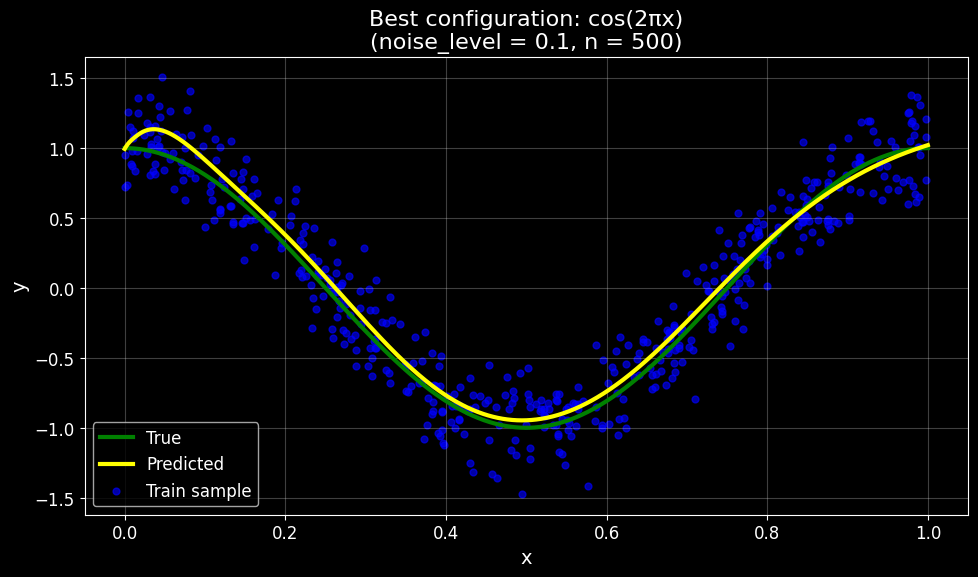

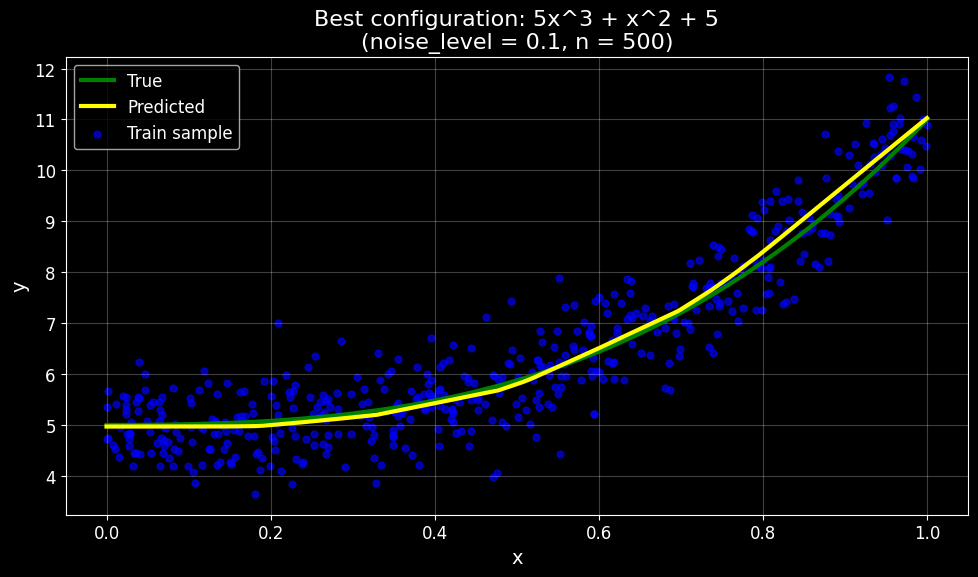

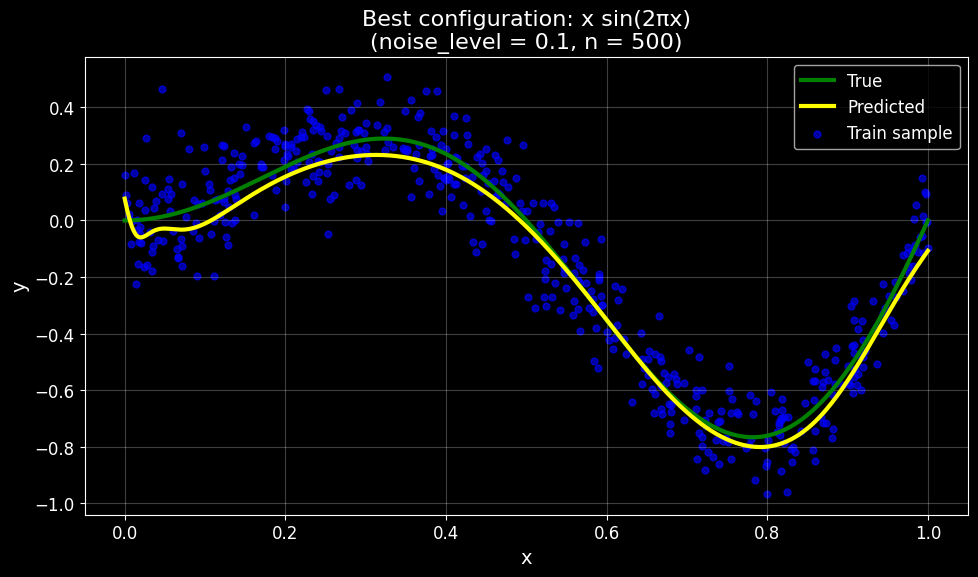

In [54]:
x_plot = np.linspace(X_MIN, X_MAX, 1000)

for func_name, func in FUNCTIONS.items():
    sample = train_samples[(func_name, DEFAULT_N, DEFAULT_NOISE)]
    y_real = func(x_plot)
    y_predicted = best_models[func_name].predict(x_plot)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(x_plot, y_real, label="True", linewidth=3, color="green")
    ax.plot(x_plot, y_predicted, label="Predicted", linewidth=3, color="yellow")
    ax.scatter(
        sample["x"],
        sample["y"],
        label=f"Train sample",
        alpha=0.65,
        s=24,
        color="blue",
    )

    ax.set_title(
        f"Best configuration: {func_name}\n"
        f"(noise_level = {DEFAULT_NOISE}, n = {DEFAULT_N})"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()
    fig.tight_layout()
    plt.show()


In [55]:
for func_name in FUNCTIONS:
    activation_rows = []

    for activation in ["sigmoid", "relu", "leaky-relu", "tanh"]:
        values = results["by_activation"][func_name][activation]
        activation_rows.append({
            "activation": activation,
            "R²": values["r2"],
            "MAPE, %": values["mape"],
            "RMSE": values["rmse"],
            "hidden_count": values["hidden_count"],
            "hidden_size": values["hidden_size"],
            "learning_rate": values["learning_rate"],
            "epochs": values["epochs"],
        })

    activation_table = pd.DataFrame(activation_rows).set_index("activation")
    print(
        f"Different activations for {func_name} "
        f"(noise_level = {DEFAULT_NOISE}, n = {DEFAULT_N})"
    )
    display(activation_table)
    print()

Different activations for cos(2πx) (noise_level = 0.1, n = 500)


,R²,"MAPE, %",RMSE,hidden_count,hidden_size,learning_rate,epochs
activation,,,,,,,
sigmoid,0.882100,48,0.244972,0,91,0.145731,21
relu,0.980129,63,0.100569,7,116,0.006555,66
leaky-relu,0.977129,45,0.107896,6,39,0.014242,21
tanh,0.990200,34,0.070626,10,116,0.000157,21



Different activations for 5x^3 + x^2 + 5 (noise_level = 0.1, n = 500)


,R²,"MAPE, %",RMSE,hidden_count,hidden_size,learning_rate,epochs
activation,,,,,,,
sigmoid,0.975440,3,0.255148,1,92,0.068811,24
relu,0.995086,1,0.114134,1,113,0.025091,23
leaky-relu,0.988236,1,0.176588,5,35,0.009560,1000
tanh,0.979405,1,0.233649,0,17,0.053136,25



Different activations for x sin(2πx) (noise_level = 0.1, n = 500)


,R²,"MAPE, %",RMSE,hidden_count,hidden_size,learning_rate,epochs
activation,,,,,,,
sigmoid,0.969699,41694,0.064686,1,94,0.151541,86
relu,0.983002,44965,0.048449,7,25,0.054280,42
leaky-relu,0.894773,35313,0.120545,5,10,0.048706,32
tanh,0.986843,104254,0.042624,9,85,0.002931,42


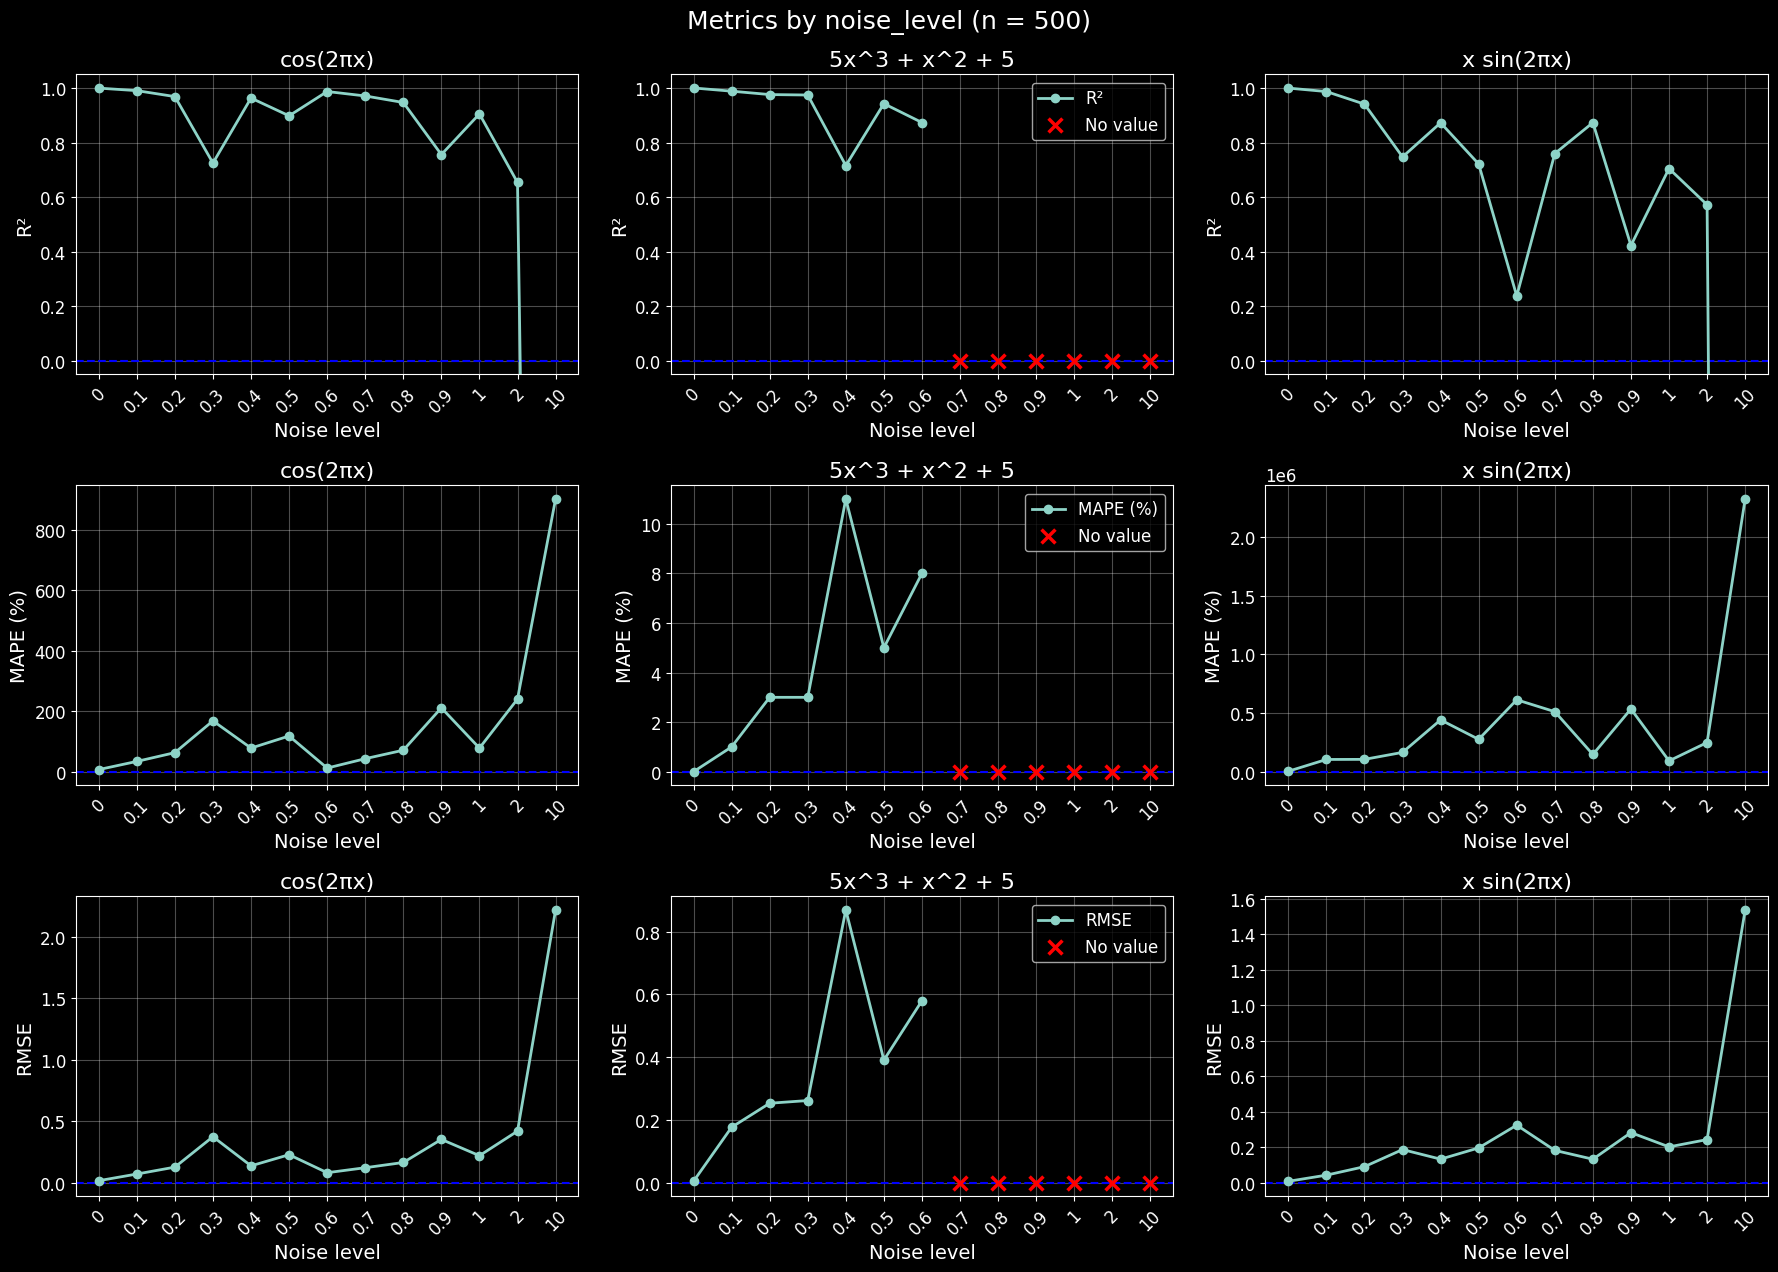

In [56]:
metrics = ["r2", "mape", "rmse"]
metric_labels = {
    "r2": "R²",
    "mape": "MAPE (%)",
    "rmse": "RMSE"
}

fig, axes = plt.subplots(3, 3, figsize=(18, 13))

x_positions = np.arange(len(NOISE_VALUES))

for col, func_name in enumerate(FUNCTIONS):
    for row, metric in enumerate(metrics):
        ax = axes[row, col]

        if metric == "r2":
            ax.set_ylim(-0.05, 1.05)
        ax.axhline(y=0, color="blue", linestyle="--", linewidth=1.5)

        values = [
            results["by_noise"][func_name][str(noise)][metric]
            for noise in NOISE_VALUES
        ]

        valid_x = [
            x_positions[i]
            for i, value in enumerate(values)
            if value is not None
        ]

        valid_y = [
            value
            for value in values
            if value is not None
        ]

        null_x = [
            x_positions[i]
            for i, value in enumerate(values)
            if value is None
        ]

        ax.plot(
            valid_x,
            valid_y,
            marker="o",
            linewidth=2,
            label=metric_labels[metric]
        )

        if null_x:
            ax.scatter(
                null_x,
                [0] * len(null_x),
                color="red",
                marker="x",
                s=100,
                linewidths=2.5,
                label="No value",
                zorder=5
            )

        ax.set_xticks(x_positions)
        ax.set_xticklabels(NOISE_VALUES, rotation=45)

        ax.set_title(func_name)
        ax.set_xlabel("Noise level")
        ax.set_ylabel(metric_labels[metric])
        ax.grid(True, alpha=0.3)

        if null_x:
            ax.legend()

fig.suptitle(
    "Metrics by noise_level (n = 500)",
    fontsize=18
)

plt.tight_layout()
plt.show()

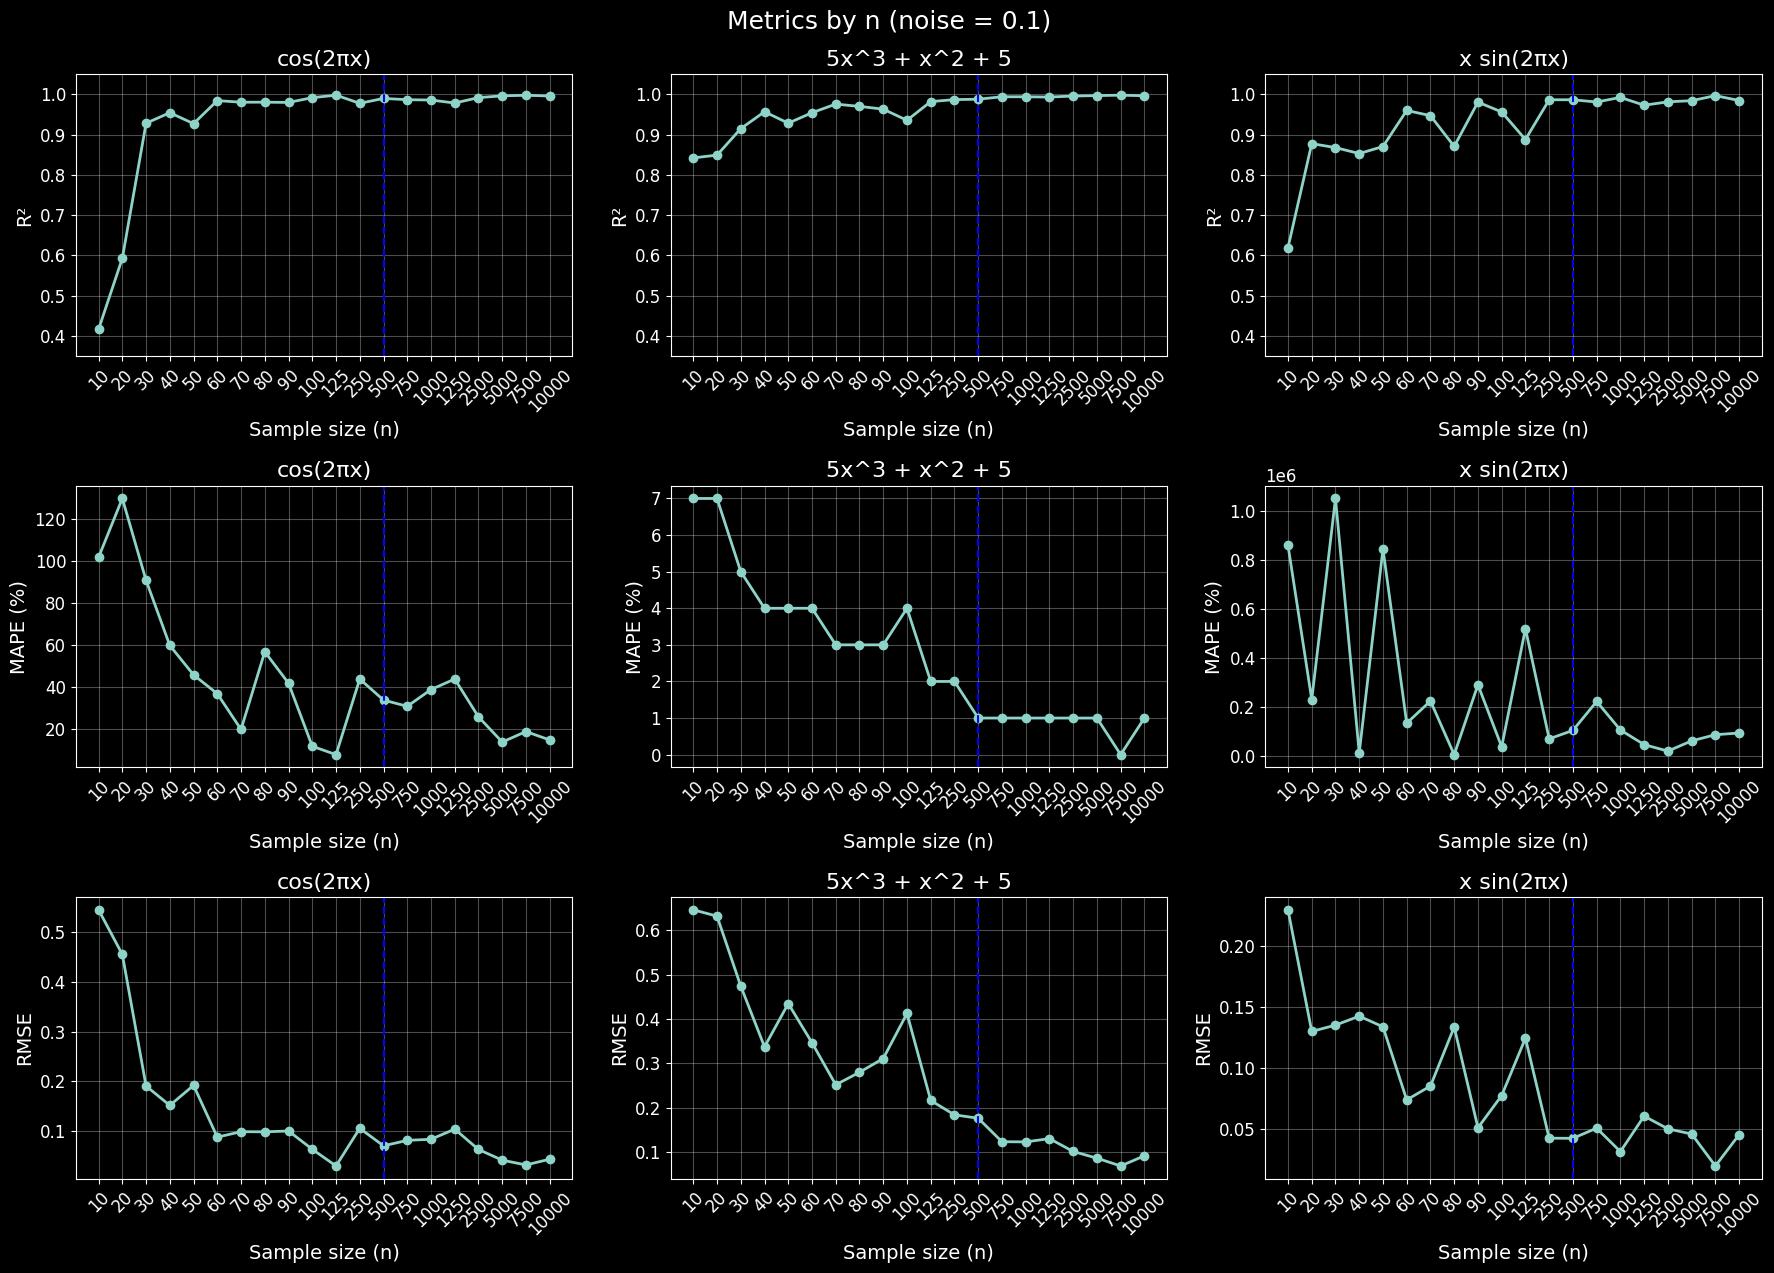

In [57]:
metrics = ["r2", "mape", "rmse"]

metric_labels = {
    "r2": "R²",
    "mape": "MAPE (%)",
    "rmse": "RMSE"
}

fig, axes = plt.subplots(3, 3, figsize=(18, 13))

x_positions = np.arange(len(N_VALUES))

for col, func_name in enumerate(FUNCTIONS):
    for row, metric in enumerate(metrics):
        ax = axes[row, col]

        values = [
            results["by_n"][func_name][str(n)][metric]
            for n in N_VALUES
        ]

        valid_x = [
            x_positions[i]
            for i, value in enumerate(values)
            if value is not None
        ]

        valid_y = [
            value
            for value in values
            if value is not None
        ]

        null_x = [
            x_positions[i]
            for i, value in enumerate(values)
            if value is None
        ]

        ax.plot(
            valid_x,
            valid_y,
            marker="o",
            linewidth=2,
            label=metric_labels[metric]
        )

        if null_x:
            ax.scatter(
                null_x,
                [0] * len(null_x),
                color="red",
                marker="x",
                s=100,
                linewidths=2.5,
                label="No value",
                zorder=5
            )

        x_DEFAULT = N_VALUES.index(DEFAULT_N)
        ax.axvline(
            x=x_DEFAULT,
            color="blue",
            linestyle="--",
            linewidth=1.5,
            label=f"n = {DEFAULT_N}"
        )

        # Настройка оси X
        ax.set_xticks(x_positions)
        ax.set_xticklabels(N_VALUES, rotation=45)

        ax.set_xlabel("Sample size (n)")
        ax.set_ylabel(metric_labels[metric])
        ax.set_title(func_name)

        ax.grid(True, alpha=0.3)

        # Ограничение шкалы R²
        if metric == "r2":
            ax.set_ylim(0.35, 1.05)
            ax.axhline(
                y=0,
                color="blue",
                linestyle="--",
                linewidth=1.5
            )

        if null_x:
            ax.legend()

fig.suptitle(
    f"Metrics by n (noise = {DEFAULT_NOISE})",
    fontsize=18
)

plt.tight_layout()
plt.show()


In [58]:
# results["by_activation"] = {}
# for func_name in configurations_by_activation:
#     results["by_activation"][func_name] = {}
#
#     for activation in ["sigmoid", "relu", "leaky-relu", "tanh"]:
#         X_train = train_samples[(func_name, DEFAULT_N, DEFAULT_NOISE)]["x"]
#         y_train = train_samples[(func_name, DEFAULT_N, DEFAULT_NOISE)]["y"]
#
#         X_test = test_samples[func_name]["x"]
#         y_test = test_samples[func_name]["y"]
#
#         conf = configurations_by_activation[func_name][activation]
#         model = Model(
#             hidden_count=conf["hidden_count"],
#             hidden_size=conf["hidden_size"],
#             learning_rate=conf["learning_rate"],
#             activation=conf["activation"],
#             epochs=conf["epochs"],
#             show_progress=False,
#             random_state=RANDOM_STATE,
#         )
#
#         r2, mape, rmse = score_model(model, X_train, y_train, X_test, y_test)
#
#         results["by_activation"][func_name][activation] = {
#             **conf,
#             "r2": r2,
#             "mape": mape,
#             "rmse": rmse,
#         }


In [59]:
# results["by_noise"] = {}
# for func_name in configurations_by_activation:
#     results["by_noise"][func_name] = {}
#
#     for noise_level in NOISE_VALUES:
#         X_train = train_samples[(func_name, DEFAULT_N, noise_level)]["x"]
#         y_train = train_samples[(func_name, DEFAULT_N, noise_level)]["y"]
#
#         X_test = test_samples[func_name]["x"]
#         y_test = test_samples[func_name]["y"]
#
#         conf = best_configurations[func_name]
#         model = Model(
#             hidden_count=conf["hidden_count"],
#             hidden_size=conf["hidden_size"],
#             learning_rate=conf["learning_rate"],
#             activation=conf["activation"],
#             epochs=conf["epochs"],
#             show_progress=False,
#             random_state=RANDOM_STATE,
#         )
#
#         try:
#             r2, mape, rmse = score_model(model, X_train, y_train, X_test, y_test)
#         except:
#             results["by_noise"][func_name][noise_level] = {
#                 **conf,
#                 "r2": None,
#                 "mape": None,
#                 "rmse": None,
#             }
#         else:
#             results["by_noise"][func_name][noise_level] = {
#                 **conf,
#                 "r2": r2,
#                 "mape": mape,
#                 "rmse": rmse,
#             }


In [60]:
# results["by_n"] = {}
# for func_name in configurations_by_activation:
#     results["by_n"][func_name] = {}
#
#     for n in N_VALUES:
#         X_train = train_samples[(func_name, n, DEFAULT_NOISE)]["x"]
#         y_train = train_samples[(func_name, n, DEFAULT_NOISE)]["y"]
#
#         X_test = test_samples[func_name]["x"]
#         y_test = test_samples[func_name]["y"]
#
#         conf = best_configurations[func_name]
#         model = Model(
#             hidden_count=conf["hidden_count"],
#             hidden_size=conf["hidden_size"],
#             learning_rate=conf["learning_rate"],
#             activation=conf["activation"],
#             epochs=conf["epochs"],
#             show_progress=False,
#             random_state=RANDOM_STATE,
#         )
#
#         try:
#             r2, mape, rmse = score_model(model, X_train, y_train, X_test, y_test)
#         except:
#             results["by_n"][func_name][n] = {
#                 **conf,
#                 "r2": None,
#                 "mape": None,
#                 "rmse": None,
#             }
#         else:
#             results["by_n"][func_name][n] = {
#                 **conf,
#                 "r2": r2,
#                 "mape": mape,
#                 "rmse": rmse,
#             }


In [61]:
# import json
#
# with open("results.json", "w") as f:
#     json.dump(results, f, indent=4)

In [62]:
#import optuna

# from sklearn.model_selection import KFold, train_test_split
# from sklearn.metrics import mean_squared_error
#
# cv = KFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=RANDOM_STATE
# )
#
# def objective(trial, X, y):
#     learning_rate = trial.suggest_float('learning_rate', 0.000001, 0.1, log=True)
#     epochs = trial.suggest_int('epochs', 1, 300)
#     activation = trial.suggest_categorical('activation', ['relu', 'leaky-relu', 'sigmoid', 'tanh'])
#     hidden_size = trial.suggest_int('hidden_size', 1, 64)
#     hidden_count = trial.suggest_int('hidden_count', 0, 5)
#
#     # for early stopping
#     patience = 10
#     scores = []
#
#     for fold, (train_idx, test_idx) in enumerate(cv.split(X)):
#         X_train = X[train_idx]
#         X_test = X[test_idx]
#
#         y_train = y[train_idx]
#         y_test = y[test_idx]
#
#         # for early stopping
#         X_inner_train, X_val, y_inner_train, y_val = train_test_split(
#             X_train,
#             y_train,
#             test_size=0.2,
#             random_state=RANDOM_STATE
#         )
#
#         model = Model(
#             hidden_count=hidden_count,
#             hidden_size=hidden_size,
#             activation=activation,
#             learning_rate=learning_rate,
#             epochs=epochs,
#             show_progress=False,
#             random_state=RANDOM_STATE,
#         )
#
#         try:
#             model.fit(
#                 X_inner_train,
#                 y_inner_train,
#                 early_stopping=True,
#                 patience=patience,
#                 X_val=X_val,
#                 y_val=y_val
#             )
#
#             predictions = model.predict(X_test)
#
#             rmse = np.sqrt(
#                 mean_squared_error(y_test, predictions)
#             )
#
#             scores.append(rmse)
#
#         except FloatingPointError:
#             return 1e10
#
#     return np.mean(scores)
#
#
# for func_name, func in FUNCTIONS.items():
#     for n in N_VALUES:
#         sampler = optuna.samplers.TPESampler(
#             seed=RANDOM_STATE,
#             n_startup_trials=40,
#             multivariate=True
#         )
#
#         study = optuna.create_study(
#             direction="minimize",
#             study_name=f"MLP_Regression(n={n}, func={func_name})",
#         )
#
#         study.optimize(
#             lambda trial: objective(
#                 trial,
#                 train_samples[(func_name, n)]["x"],
#                 train_samples[(func_name, n)]["y"],
#             ),
#             n_trials=200,
#             show_progress_bar=False
#         )
